# 🦙 LlamaIndex: From Zero to a Working RAG Chatbot

**Level:** Beginner → Intermediate  | **Format:** Theory → Analogy → Live Code → Practice → Interview Questions

**Learning outcomes:** Understand LlamaIndex, documents/nodes, loading, chunking, embeddings, indexing, retrieval, response generation, source tracing, and saving an index. Build a small **company policy assistant** without having to find a dataset.


## 1. What is LlamaIndex?
**LlamaIndex is a framework that helps LLM-powered apps work with your own information**—documents, databases and other sources.

**Simple analogy:** Imagine a librarian. You give the librarian 100 documents and ask a question. Rather than reading every document aloud, the librarian finds the relevant pages and hands them to a writer (the LLM). The writer gives you a clear answer based on those pages.

**Important distinction:**
- **LlamaIndex** = the librarian/workflow connecting your data to AI.
- **Embedding model** = converts text to numbers representing meaning.
- **Vector index/store** = makes similar information easier to find.
- **LLM** = produces the final natural-language answer.

### Two paths in a RAG app
**Ingestion (usually done when data is added):** Files → Documents → Chunks/Nodes → Embeddings → Index

**Question answering (done for each question):** Question → Question embedding → Retrieve nodes → Give evidence to LLM → Answer

RAG stands for *Retrieval-Augmented Generation*: **retrieve** relevant evidence, then **generate** an answer.

## 2. Installation and requirements
Use **Python 3.10+** in a Jupyter Notebook or VS Code. Install dependencies in this kernel. Restart the kernel if imports fail after installation.

The example below explicitly selects `gpt-4o-mini` and `text-embedding-3-small`, avoiding implicit model defaults. You need an OpenAI API key with available credits. Never publish your key in a notebook.

In [1]:
%pip install -q -U llama-index-core llama-index-llms-openai llama-index-embeddings-openai llama-index-readers-file pypdf

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## 3. Create our sample data (works without a PDF)
Think of this as a small company handbook. Running the cell creates a `data/` folder with three `.txt` policy documents. You can later add your own PDFs to the same folder.

In [2]:
from pathlib import Path

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

sample_policies = {
    "leave_policy.txt": """LihaTech Demo Company - Leave Policy (Fictional)
Employees receive 12 casual leave days per calendar year. Employees should apply
at least 2 working days in advance for planned casual leave. Emergency leave
should be communicated to the manager as soon as possible. Unused casual
leave cannot be carried forward to the next calendar year.
""",
    "remote_work_policy.txt": """LihaTech Demo Company - Remote Work Policy (Fictional)
Employees may work remotely up to 2 days per week with manager approval.
Remote employees must be available from 10:00 AM to 4:00 PM on working days.
Company devices must be protected with passwords and MFA.
""",
    "training_policy.txt": """LihaTech Demo Company - Training Policy (Fictional)
Employees receive a training budget of INR 10000 per calendar year, subject
to manager approval. Reimbursement requires a receipt and proof of completion.
Requests should be submitted within 30 days after finishing training.
""",
}

for filename, content in sample_policies.items():
    (DATA_DIR / filename).write_text(content, encoding="utf-8")

print("Demo files:", [p.name for p in DATA_DIR.iterdir() if p.is_file()])

Demo files: ['leave_policy.txt', 'remote_work_policy.txt', 'training_policy.txt']


## 4. Configure the models safely
We use **getpass** to enter an API key privately, without writing it to the notebook. If `OPENAI_API_KEY` already exists in your environment, no prompt is needed.

**Cost note:** Creating embeddings and asking the LLM can incur API charges. Run index creation once, then persist it for reuse.

In [3]:
import os
from getpass import getpass
from llama_index.core import Settings
from llama_index.llms.openai import OpenAI
from llama_index.embeddings.openai import OpenAIEmbedding

if not os.getenv("OPENAI_API_KEY"):
    os.environ["OPENAI_API_KEY"] = getpass("Enter your OpenAI API key: ").strip()
if not os.environ["OPENAI_API_KEY"]:
    raise ValueError("OPENAI_API_KEY is required for this OpenAI-based example.")

Settings.llm = OpenAI(model="gpt-4o-mini", temperature=0)
Settings.embed_model = OpenAIEmbedding(model="text-embedding-3-small")
print("Models configured. API key is not displayed.")

Models configured. API key is not displayed.


## 5. Load documents
**Document:** A unit of source content (text plus metadata). **Metadata:** Helpful information such as a file name. Think of metadata as the label on a library book.

`SimpleDirectoryReader` loads supported files in a directory. For scanned/image-only PDFs you generally need OCR or a specialized parser; the standard reader alone may not extract their text.

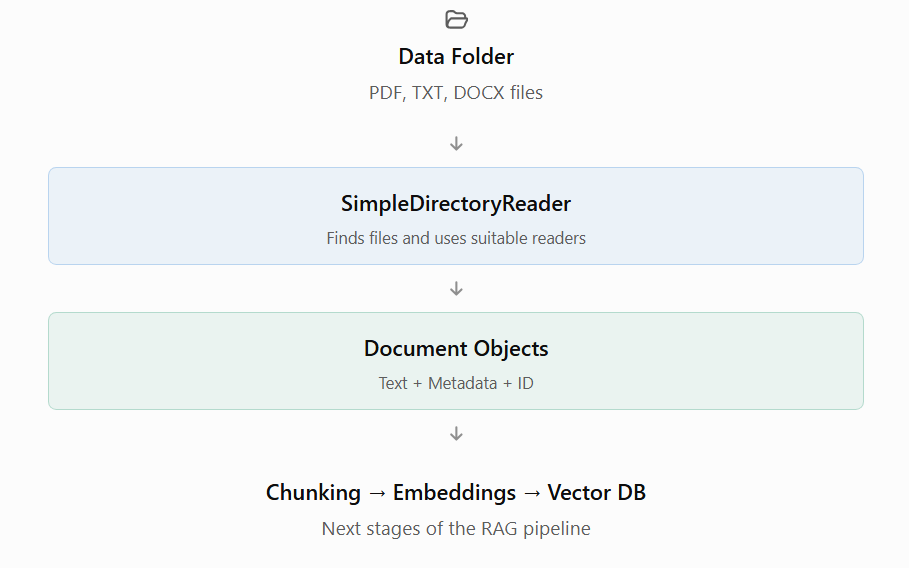

In [4]:
from llama_index.core import SimpleDirectoryReader

documents = SimpleDirectoryReader(input_dir=str(DATA_DIR)).load_data()
print("Loaded document objects:", len(documents))
for doc in documents:
    print("File:", doc.metadata.get("file_name", "unknown"), "| Characters:", len(doc.text))
print("\nFirst 250 characters:\n", documents[0].text[:250])

Loaded document objects: 3
File: leave_policy.txt | Characters: 344
File: remote_work_policy.txt | Characters: 267
File: training_policy.txt | Characters: 281

First 250 characters:
 LihaTech Demo Company - Leave Policy (Fictional)
Employees receive 12 casual leave days per calendar year. Employees should apply
at least 2 working days in advance for planned casual leave. Emergency leave
should be communicated to the manager as


In [5]:
documents

[Document(id_='3f2dcb62-5eb5-4d15-a760-1cda85802651', embedding=None, metadata={'file_path': 'd:\\AIML\\gen_ai\\data\\leave_policy.txt', 'file_name': 'leave_policy.txt', 'file_type': 'text/plain', 'file_size': 344, 'creation_date': '2026-10-09', 'last_modified_date': '2026-10-09'}, excluded_embed_metadata_keys=['file_name', 'file_type', 'file_size', 'creation_date', 'last_modified_date', 'last_accessed_date'], excluded_llm_metadata_keys=['file_name', 'file_type', 'file_size', 'creation_date', 'last_modified_date', 'last_accessed_date'], relationships={}, metadata_template='{key}: {value}', metadata_separator='\n', text_resource=MediaResource(embeddings=None, data=None, text='LihaTech Demo Company - Leave Policy (Fictional)\r\nEmployees receive 12 casual leave days per calendar year. Employees should apply\r\nat least 2 working days in advance for planned casual leave. Emergency leave\r\nshould be communicated to the manager as soon as possible. Unused casual\r\nleave cannot be carried 

## 6. Split documents into smaller nodes
**Why split?** A large document can contain many topics. Smaller pieces let retrieval focus on the part that addresses the question.

- `chunk_size`: target maximum size of a text chunk, measured here in **tokens** (not characters).
- `chunk_overlap`: number of tokens repeated between adjacent chunks, useful when a sentence spans a boundary.
- `Node`: an indexed piece of content that may retain source metadata.

**Analogy:** Instead of searching an entire textbook, search its individual paragraphs. Avoid making chunks so tiny that they lose meaning or so large that they mix many subjects.

In [6]:
from llama_index.core.node_parser import SentenceSplitter

splitter = SentenceSplitter(chunk_size=128, chunk_overlap=20)
nodes = splitter.get_nodes_from_documents(documents)
print("Documents:", len(documents), "| Nodes:", len(nodes))
for i, node in enumerate(nodes[:3], start=1):
    print(f"\nNode {i} | source: {node.metadata.get('file_name', 'unknown')}")
    print(node.text[:300])

Documents: 3 | Nodes: 3

Node 1 | source: leave_policy.txt
LihaTech Demo Company - Leave Policy (Fictional)
Employees receive 12 casual leave days per calendar year. Employees should apply
at least 2 working days in advance for planned casual leave. Emergency leave
should be communicated to the manager as soon as possible. Unused casual
leave cannot be 

Node 2 | source: remote_work_policy.txt
LihaTech Demo Company - Remote Work Policy (Fictional)
Employees may work remotely up to 2 days per week with manager approval.
Remote employees must be available from 10:00 AM to 4:00 PM on working days.
Company devices must be protected with passwords and MFA.

Node 3 | source: training_policy.txt
LihaTech Demo Company - Training Policy (Fictional)
Employees receive a training budget of INR 10000 per calendar year, subject
to manager approval. Reimbursement requires a receipt and proof of completion.
Requests should be submitted within 30 days after finishing training.


## 7. Build a vector index
The embedding model converts every node into a numeric vector. The vector index uses those vectors to find semantically related text.

**Example:** “How many vacation days?” could find a passage about “casual leave” even without exact word matching.

LlamaIndex's default simple vector index can live in memory; persisting it later writes index data to disk. For production-scale RAG, teams often connect an external vector database.

In [7]:
from llama_index.core import VectorStoreIndex

index = VectorStoreIndex(nodes, embed_model=Settings.embed_model, show_progress=True)
print("Vector index ready!")

d:\AIML\gen_ai\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Generating embeddings: 100%|██████████| 3/3 [00:08<00:00,  2.81s/it]

Vector index ready!


## 8. Retrieval only (no answer generation)
**Retriever:** Finds relevant nodes. **`similarity_top_k=2`** means ask for up to two matching nodes. Inspect the evidence **before** involving an LLM: it is easier to debug a retrieval problem separately from a generation problem.

Similarity scores are ranking signals, not guaranteed probabilities or a universal “confidence percentage.”

In [8]:
retriever = index.as_retriever(similarity_top_k=2)
question = "How many casual leave days do employees receive?"
results = retriever.retrieve(question)
for i, item in enumerate(results, start=1):
    print(f"Match {i} | score={item.score} | file={item.node.metadata.get('file_name')}")
    print(item.node.text[:500], "\n")

2026-10-09 11:12:39,255 - INFO - HTTP Request: POST https://api.openai.com/v1/embeddings "HTTP/1.1 200 OK"


Match 1 | score=0.6603894780593214 | file=leave_policy.txt
LihaTech Demo Company - Leave Policy (Fictional)
Employees receive 12 casual leave days per calendar year. Employees should apply
at least 2 working days in advance for planned casual leave. Emergency leave
should be communicated to the manager as soon as possible. Unused casual
leave cannot be carried forward to the next calendar year. 

Match 2 | score=0.342114287657902 | file=remote_work_policy.txt
LihaTech Demo Company - Remote Work Policy (Fictional)
Employees may work remotely up to 2 days per week with manager approval.
Remote employees must be available from 10:00 AM to 4:00 PM on working days.
Company devices must be protected with passwords and MFA. 



## 9. Retrieval + LLM = question answering
**Query Engine:** Brings retrieval and response generation together. First it retrieves useful passages; then the LLM writes an answer using them.

Check the **source nodes** rather than blindly assuming an answer is correct. A model may still make mistakes or infer facts not supported by the sources.

In [ ]:
query_engine = index.as_query_engine(similarity_top_k=2)
response = query_engine.query("How many casual leaves do employees get each year?")
print("Answer:\n", response)
print("\nSources:")
for hit in response.source_nodes:
    print("-", hit.node.metadata.get("file_name", "unknown"), "| score:", hit.score)

## 10. Ask multiple questions and test a question outside the documents
Questions about **leave, remote work, and training** should be supported by the fictional data. The last question is not documented; verify that the assistant does not invent an answer.

For higher-stakes use cases, add explicit evidence checks, confidence calibration, and human review.

In [ ]:
questions = [
    "How many days each week can employees work remotely?",
    "What is the annual training budget?",
    "Can unused casual leave be carried forward?",
    "What is the company CEO's favorite food?",
]
for q in questions:
    answer = query_engine.query(q)
    print("QUESTION:", q)
    print("ANSWER:", str(answer), "\n")

## 11. Save and reopen the index
**Persist:** Save your prepared index so you don't re-embed the same files every time you start the notebook.

**Important:** When reopening, configure the **same embedding model**, or retrieval quality/compatibility can suffer. Do not rebuild the index before loading it unless source data has changed.

In [9]:
from llama_index.core import StorageContext, load_index_from_storage

PERSIST_DIR = "./storage"
index.storage_context.persist(persist_dir=PERSIST_DIR)
print("Saved to", PERSIST_DIR)

storage_context = StorageContext.from_defaults(persist_dir=PERSIST_DIR)
reloaded_index = load_index_from_storage(storage_context, embed_model=Settings.embed_model)
reloaded_engine = reloaded_index.as_query_engine(similarity_top_k=2)
print(reloaded_engine.query("When must training reimbursements be submitted?"))

2026-10-09 11:14:57,749 - INFO - Loading all indices.


Saved to ./storage


2026-10-09 11:15:00,704 - INFO - HTTP Request: POST https://api.openai.com/v1/embeddings "HTTP/1.1 200 OK"
2026-10-09 11:15:12,767 - INFO - HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"


Training reimbursements must be submitted within 30 days after finishing the training.


## 12. Optional: Use a real PDF
Copy a **text-based** PDF into the `data/` directory and run the cell below. Avoid placing confidential documents in this demo if you're using a third-party hosted embedding or LLM API.

If your PDF consists of scanned images, apply OCR first. More complex PDFs with tables/diagrams may require specialized parsing.

In [10]:
pdf_files = sorted(DATA_DIR.glob("*.pdf"))
if not pdf_files:
    print("No PDF found. Add a PDF to the 'data' folder and rerun this cell.")
else:
    pdf_documents = SimpleDirectoryReader(input_files=[str(pdf_files[0])]).load_data()
    print("Loaded", len(pdf_documents), "document objects from", pdf_files[0].name)
    print(pdf_documents[0].text[:400] if pdf_documents else "No readable text found")

No PDF found. Add a PDF to the 'data' folder and rerun this cell.


## 13. Key LlamaIndex components — quick reference

| Component | In simple words | Where we used it |
|---|---|---|
| `SimpleDirectoryReader` | Opens and reads files | Loading |
| `Document` | Raw readable content plus metadata | After loading |
| `SentenceSplitter` | Cuts a document into chunks | Chunking |
| `Node` | A chunk ready for indexing/retrieval | After splitting |
| `OpenAIEmbedding` | Transforms text into numeric vectors | Embeddings |
| `VectorStoreIndex` | Builds searchable index | Indexing |
| `Retriever` | Finds relevant passages | Retrieval |
| `QueryEngine` | Retrieves and asks LLM to respond | Question answering |
| `StorageContext` | Helps store/reload index | Persistence |
| `Settings` | Sets shared model defaults | Configuration |

**Common confusion:** A query engine is not the LLM itself. It coordinates retrieval plus answer synthesis.

## 14. LlamaIndex vs LangChain - comparison

| Topic | LlamaIndex | LangChain |
|---|---|---|
| Primary appeal | Data ingestion, indexing, retrieval, RAG | General LLM application integrations and workflows |
| Document loaders | Yes | Yes |
| Chunking | Yes | Yes |
| Embedding / vector DB integrations | Yes | Yes |
| RAG question answering | Yes | Yes |
| Agents and tools | Yes | Yes |
| Can use together? | **Yes** | **Yes** |

**How to teach it:** Build one small RAG application with LlamaIndex, then reproduce it in LangChain. Compare *components and debugging*, not simply the number of lines of code.

Neither is universally “better.” Choose based on required integrations, control, developer experience, and operations.

## 15. Guided practice assignments
**Assignment A — Basic:** Add a fourth text file, `holiday_policy.txt`, containing a fictional holiday policy. Rebuild the index and query how many holidays employees get.

**Assignment B — Retrieval:** Try `similarity_top_k=1` vs `similarity_top_k=3`. Print the source nodes for the same question. Did the retrieved evidence change?

**Assignment C — Chunking:** Change `chunk_size` to 64 and 256. Record how many nodes each setting creates. Why do counts differ?

**Assignment D — Grounding:** Ask an intentionally unsupported question and evaluate whether the answer is grounded. Propose one way to handle it safely.

**Assignment E — PDF:** Add your own non-confidential text-based PDF. Read it, create nodes, rebuild the vector index, and display document filenames as sources.

**Challenge:** Create a Streamlit front end with a textbox, Ask button, answer, and expandable list of retrieved sources.

### Practical evaluation worksheet

| Question | Expected fact | Answer correct? | Source relevant? |
|---|---|---|---|
| Casual leaves/year | 12 days | Fill in | Fill in |
| Remote days/week | Up to 2 days, approval required | Fill in | Fill in |
| Annual training budget | INR 10,000 | Fill in | Fill in |
| CEO's favorite food | Not mentioned | Fill in | Fill in |

## 16. Ten interview questions with short answers

1. **What is LlamaIndex?** A framework for connecting LLM applications with external data and retrieval pipelines.
2. **What is a Document?** Source content plus metadata.
3. **What is a Node?** A piece of source content, commonly a chunk, which can preserve metadata and relationships.
4. **Why chunk text?** To improve retrieval granularity and fit model input constraints.
5. **What is an embedding?** A numeric representation used for semantic similarity.
6. **What does `VectorStoreIndex` do?** Indexes embeddings of nodes for similarity-based retrieval.
7. **Retriever vs Query Engine?** A retriever returns matching nodes; a query engine can retrieve and generate a response.
8. **What does `similarity_top_k` mean?** Maximum number of top matching nodes requested from retrieval.
9. **Does RAG guarantee truth?** No. Retrieval errors and hallucinations still happen; verify evidence.
10. **LlamaIndex vs LangChain?** Both support RAG; LlamaIndex focuses strongly on data-centric indexing and retrieval workflows, while LangChain also targets broader LLM application orchestration.

**Bonus interview scenario:** “Your PDF chatbot gives wrong answers.” Suggested checks: extraction quality → text chunks → metadata → retrieved passages → embedding choice → query settings → response prompt → evaluation examples.

## 17. Conclusion: what have we built?
You created a small RAG workflow:

`Fictional policy files → Documents → Nodes → Embeddings → VectorStoreIndex → Retriever → QueryEngine → Answer + Sources`

**Trainer recap:**
- LlamaIndex is an **orchestration/data framework**, not an LLM or vector database.
- Good retrieval comes from good source data, sensible chunks, suitable embeddings, and evaluation.
- Always inspect sources before trusting generated answers.
- Persist your index to avoid unnecessary repeated embedding calls.

### Official reference links
- [LlamaIndex starter tutorial](https://developers.llamaindex.ai/python/framework/getting_started/starter_example/)
- [SimpleDirectoryReader](https://developers.llamaindex.ai/python/framework/module_guides/loading/simpledirectoryreader/)
- [Embeddings guide](https://developers.llamaindex.ai/python/framework/module_guides/models/embeddings/)
- [LlamaIndex GitHub repository](https://github.com/run-llama/llama_index)

*Prepared for beginner-friendly live training. Model/API behavior and package versions may evolve; refer to current official docs when updating the lesson.*